# DỰ ÁN: PHÂN TÍCH CHẤT LƯỢNG KHÔNG KHÍ HÀ NỘI

# Phần 2: Phân tích khám phá dữ liệu – Ảnh hưởng của điều kiện thời tiết tới AQI
Tác giả: Nam Aaron Nguyen
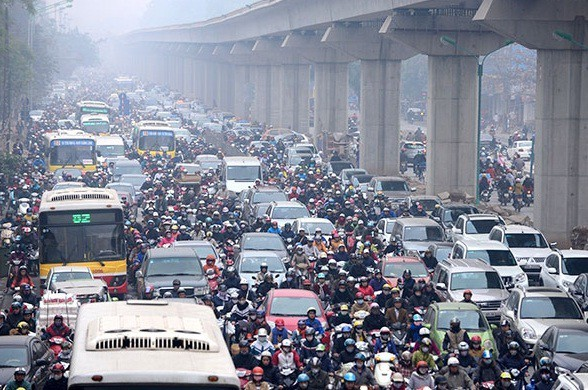

# **Giới thiệu**

Trong notebook này, tôi sẽ đi sâu vào bộ dữ liệu, phân tích dữ liệu lịch sử và tìm hiểu ảnh hưởng của điều kiện thời tiết tới chất lượng không khí của Hà Nội.

## Mô tả bộ dữ liệu

Bộ dữ liệu gồm dữ liệu theo giờ với 8785 dòng và 18 cột, trải dài từ **00:00:00 ngày 08/03/2023** đến **00:00:00 ngày 08/03/2024**. Không có điểm dữ liệu nào bị thiếu trong DataFrame.

## Định nghĩa các cột

**Các cột chất lượng không khí**
- AQI: Chỉ số chất lượng không khí (Air Quality Index)
- CO: Carbon monoxide (mg/$m^{3}$)
- NO2: Nitơ dioxide (ug/$m^{3}$)
- O3: Ozone (ug/$m^{3}$)
- PM10: Bụi mịn có đường kính ≤ 10 µm (ug/$m^{3}$)
- PM25: Bụi mịn có đường kính ≤ 2.5 µm (ug/$m^{3}$)
- SO2: Lưu huỳnh dioxide (ug/$m^{3}$)

**Các cột thời tiết**
- Clouds: Độ che phủ mây (%)
- Precipitation: Lượng mưa (mm)
- Pressure: Áp suất khí quyển (hPa)
- Relative Humidity: Độ ẩm tương đối (%)
- Temperature: Nhiệt độ (°C)
- UV Index: Chỉ số tia cực tím
- Wind Speed: Tốc độ gió (m/s)

# I. Import thư viện

In [1]:
import requests
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
import seaborn as sns
import plotly.express as px

%matplotlib inline


# II. Đọc dữ liệu

In [2]:
# Đọc file CSV vào DataFrame
df = pd.read_csv('Data/hanoi-aqi-weather-data.csv')  # Đường dẫn tới file CSV được tạo ở Part 1

# Chuyển cột 'Local Time' sang kiểu datetime
df['Local Time'] = pd.to_datetime(df['Local Time'])

# Đặt cột 'Local Time' làm index
df.set_index('Local Time', inplace=True)

# Hiển thị DataFrame
df  # Dùng df.head() để chỉ xem vài dòng đầu

,UTC Time,City,Country Code,Timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
Local Time,,,,,,,,,,,,,,,,,,
2023-03-08 00:00:00,2023-03-07T17:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,131,170.6,29.3,53.3,58.8,47.00,67.3,91,0.0,1016,86,21.2,0.0,2.00
2023-03-08 01:00:00,2023-03-07T18:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,158.7,25.0,54.0,56.3,45.00,65.0,100,0.0,1016,89,21.1,0.0,2.00
2023-03-08 02:00:00,2023-03-07T19:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,150.2,21.7,55.0,52.5,42.00,65.7,100,0.0,1016,90,20.9,0.0,1.66
2023-03-08 03:00:00,2023-03-07T20:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,141.6,18.3,56.0,56.3,45.00,66.3,100,0.0,1016,91,20.7,0.0,1.33
2023-03-08 04:00:00,2023-03-07T21:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,133.1,15.0,57.0,52.5,42.00,67.0,100,0.0,1015,92,20.5,0.0,1.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-03-07 20:00:00,2024-03-07T13:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,193,6738.4,36.7,21.4,139.3,87.86,12.0,100,0.0,1014,71,21.5,0.0,1.00
2024-03-07 21:00:00,2024-03-07T14:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,173,6693.2,29.3,19.5,140.6,73.00,6.0,100,0.0,1015,75,21.1,0.0,1.00
2024-03-07 22:00:00,2024-03-07T15:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,241,504.0,108.0,18.4,167.0,124.00,116.0,100,0.0,1016,80,20.6,0.0,1.00


# III. Phân tích khám phá dữ liệu (EDA)

Ở phần này, phân tích khám phá dữ liệu (EDA) được dùng để xem xét dữ liệu nhằm tìm ra các quy luật, phát hiện điểm bất thường, kiểm định giả thuyết và xác nhận các giả định thông qua thống kê mô tả và biểu đồ.

Trong 45 năm qua, Chỉ số chất lượng không khí (AQI) do Cơ quan Bảo vệ Môi trường Hoa Kỳ (USEPA) xây dựng đã cung cấp thông tin quan trọng cho cộng đồng về tình trạng ô nhiễm không khí. AQI được tính dựa trên nồng độ đo được của Carbon monoxide (CO), Nitơ dioxide (NO2), Ozone (O3), bụi mịn (PM2.5 và PM10) và Lưu huỳnh dioxide (SO2).

PM2.5 – bụi mịn có đường kính từ 2.5 micromet trở xuống – là tác nhân gây hại sức khỏe hàng đầu và thường được dùng làm tiêu chí trong các quy chuẩn về chất lượng không khí.

Theo [Báo cáo Chất lượng không khí thế giới 2019 của IQAir](https://www.iqair.com/world-most-polluted-cities/world-air-quality-report-2019-en.pdf), mức PM2.5 được phân nhóm để xác định tình trạng chất lượng không khí như sau:
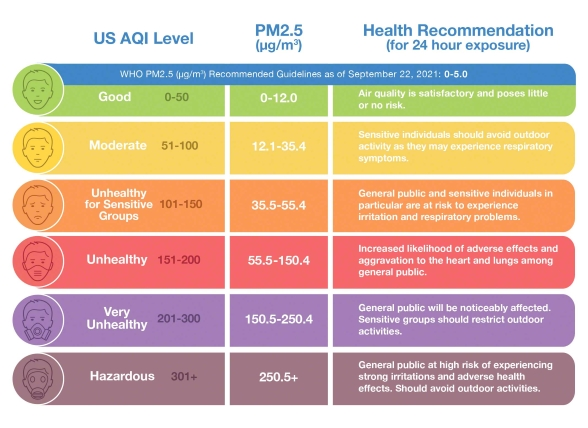

## 3.1. Thống kê mô tả

In [3]:
df.describe()

,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
count,8785.000000,8785.000000,8785.000000,8785.000000,8785.000000,8785.000000,8785.000000,8785.000000,8785.000000,8785.000000,8785.000000,8785.000000,8785.000000,8785.000000
mean,117.625612,436.146238,27.913887,62.308310,62.310939,49.401244,75.815822,72.992032,0.274132,1010.006602,78.043142,25.281172,1.332863,1.606777
std,53.380563,985.528684,34.063995,45.703768,57.237488,47.699812,45.197389,28.450636,1.029955,7.432832,15.373435,5.649272,1.975192,0.781160
min,21.000000,9.000000,2.000000,0.000000,1.300000,1.000000,0.000000,0.000000,0.000000,994.000000,17.000000,8.600000,0.000000,0.000000
25%,78.000000,124.700000,11.000000,28.100000,31.300000,24.670000,44.000000,58.000000,0.000000,1004.000000,68.000000,21.600000,0.000000,1.000000
50%,104.000000,169.000000,16.700000,52.000000,46.300000,36.000000,70.300000,80.000000,0.000000,1009.000000,82.000000,26.100000,0.600000,1.600000
75%,151.000000,269.200000,28.000000,85.000000,70.000000,55.000000,103.000000,100.000000,0.000000,1016.000000,91.000000,29.200000,2.000000,2.000000
max,500.000000,15956.200000,378.000000,262.000000,604.000000,446.000000,368.000000,100.000000,22.750000,1033.000000,100.000000,40.000000,12.100000,5.200000


*Trung bình, AQI của Hà Nội ở mức 117.63, thuộc nhóm "Không tốt cho nhóm nhạy cảm" (Unhealthy for Sensitive Groups). Tuy nhiên, có những thời điểm AQI tăng vọt lên giá trị tối đa 500, chạm mức "Nguy hại" (Hazardous). Tương tự, chỉ số PM2.5 trung bình là 49.4 µg/m³, cũng thuộc mức "Không tốt cho nhóm nhạy cảm". Về lượng mưa, nếu chỉ dựa vào thống kê mô tả thì chưa thể khẳng định Hà Nội có phải là một trong những thành phố mưa nhiều nhất hay không. Áp suất khí quyển trung bình của Hà Nội khoảng 1010 hPa, gần bằng áp suất tiêu chuẩn (1013 hPa). Với độ ẩm trung bình 78.05%, Hà Nội thuộc nhóm thành phố ẩm nhất châu Á. Ngoài ra, nhiệt độ trung bình 25.3℃ cho thấy thành phố có khí hậu ấm áp quanh năm.*

## 3.2. Chỉ số chất lượng không khí (AQI)

### 3.2.1. AQI theo giờ của Hà Nội trong năm

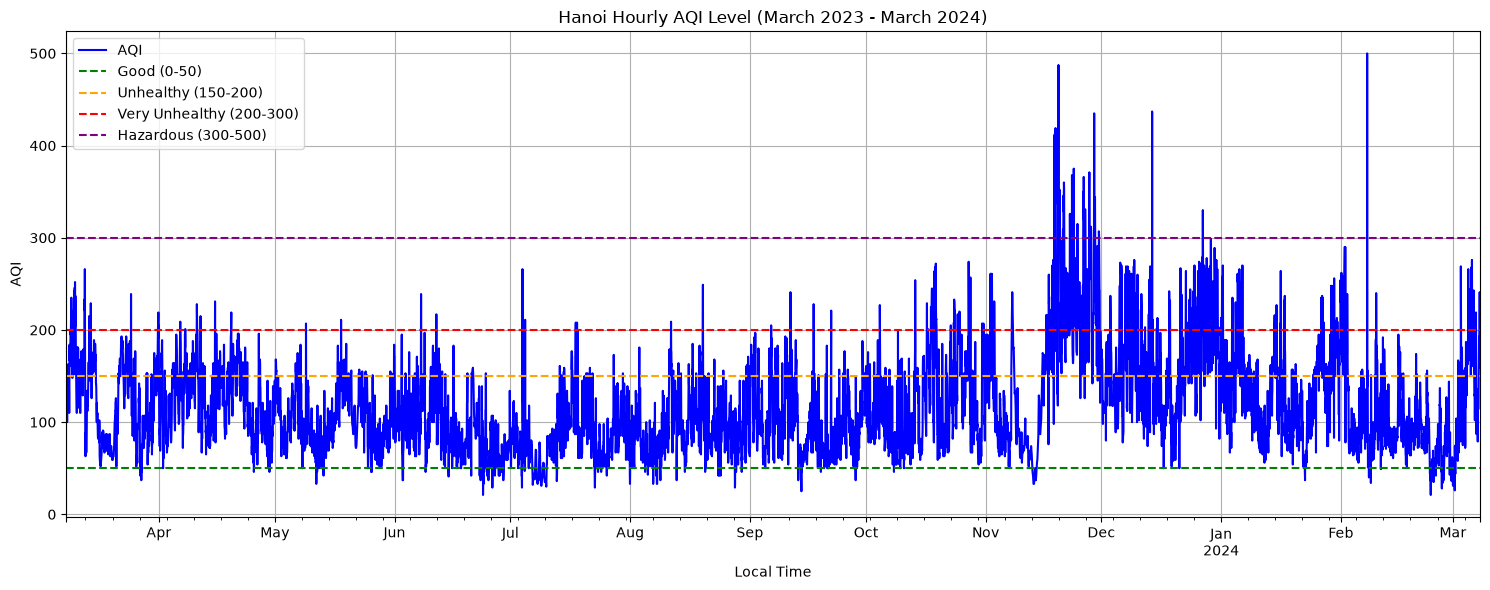

Time with the highest AQI level: (Timestamp('2024-02-07 19:00:00'), np.int64(500))


In [4]:
# Vẽ biểu đồ đường chuỗi thời gian AQI
plt.figure(figsize=(15, 6))
df['AQI'].plot(kind='line', color='b')

# Thêm nhãn trục và tiêu đề
plt.xlabel('Local Time')
plt.ylabel('AQI')
plt.title('Hanoi Hourly AQI Level (March 2023 - March 2024)')
# Thêm các đường ngang thể hiện ngưỡng mức độ ô nhiễm
plt.axhline(y=50, color='green', linestyle='--', label='Good (0-50)')
plt.axhline(y=150, color='orange', linestyle='--', label='Unhealthy (150-200)')
plt.axhline(y=200, color='red', linestyle='--', label='Very Unhealthy (200-300)')
plt.axhline(y=300, color='purple', linestyle='--', label='Hazardous (300-500)')

# Hiển thị chú thích
plt.legend()
# Hiển thị biểu đồ
plt.grid(True)
plt.tight_layout()
plt.show()

# Tìm thời điểm có chỉ số AQI cao nhất
highest_aqi_time = df['AQI'].idxmax(), df['AQI'].max()
print("Time with the highest AQI level:", highest_aqi_time)

*Từ biểu đồ có thể thấy AQI của Hà Nội chủ yếu dao động trong khoảng 50-150 (từ mức "Trung bình" đến "Không tốt cho nhóm nhạy cảm"). Chỉ số hiếm khi nằm trong vùng "Tốt" (0-50) và thường xuyên vượt ngưỡng "Có hại cho sức khỏe" (Unhealthy). Đặc biệt, chỉ số đạt mức "Nguy hại" (>300) vào nhiều thời điểm từ tháng 11 đến giữa tháng 2, và đạt đỉnh cao nhất trong năm lúc 19h ngày 07/02/2024.*

*Nhìn chung, Hà Nội đã phải đối mặt với tình trạng ô nhiễm không khí nghiêm trọng trong năm qua, điều này có thể ảnh hưởng nặng nề tới sức khỏe người dân.*

### 3.2.2. AQI theo giờ của Hà Nội trong các tháng có mức AQI nguy hại

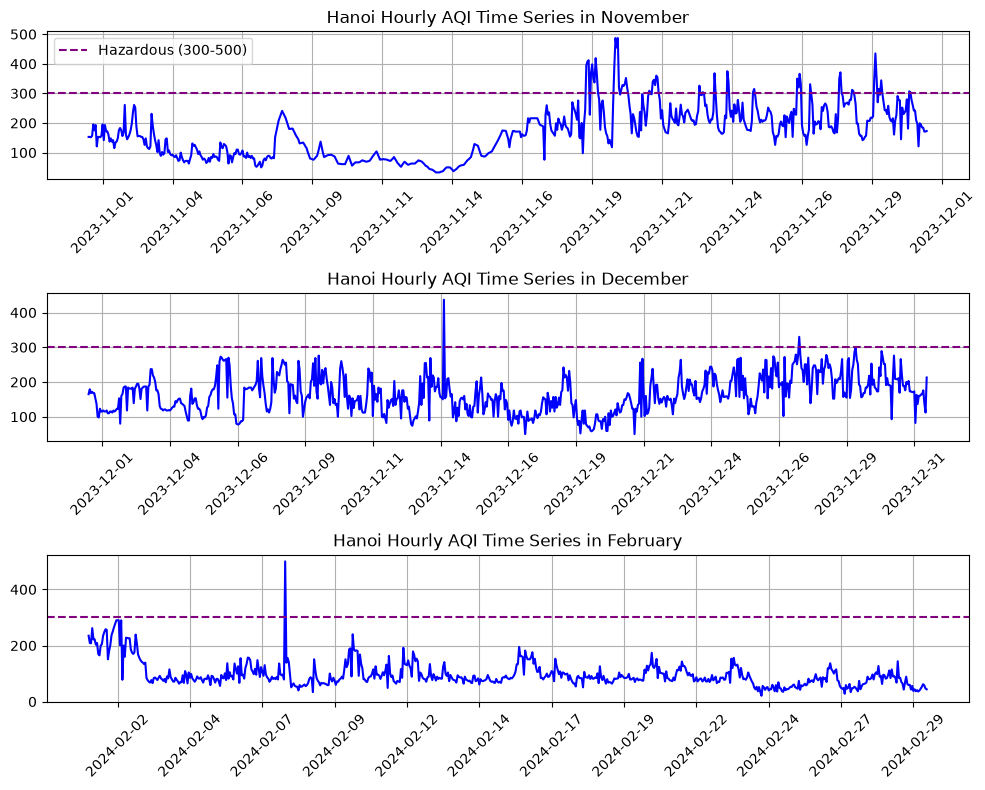

In [5]:
# Tạo các biểu đồ con
fig, axs = plt.subplots(3, 1, figsize=(10, 8))

# Biểu đồ đường AQI tháng 11
axs[0].plot(df['2023-11-01':'2023-11-30']["AQI"], color='b')
axs[0].set_title('Hanoi Hourly AQI Time Series in November')
axs[0].grid(True)
axs[0].axhline(y=300, color='purple', linestyle='--', label='Hazardous (300-500)')
axs[0].legend()

# Biểu đồ đường AQI tháng 12
axs[1].plot(df['2023-12-01':'2023-12-31']["AQI"], color='b')
axs[1].set_title('Hanoi Hourly AQI Time Series in December')
axs[1].grid(True)
axs[1].axhline(y=300, color='purple', linestyle='--', label='Hazardous (300-500)')

# Biểu đồ đường AQI tháng 2
axs[2].plot(df['2024-02-01':'2024-02-29']["AQI"], color='b')
axs[2].set_title('Hanoi Hourly AQI Time Series in February')
axs[2].grid(True)
axs[2].axhline(y=300, color='purple', linestyle='--', label='Hazardous (300-500)')

# Chỉ hiển thị tối đa 15 vạch chia trên trục x
for ax in axs:
    ax.xaxis.set_major_locator(plt.MaxNLocator(15))

# Xoay nhãn trục x
for ax in axs:
    ax.tick_params(axis='x', rotation=45)

# Hiển thị biểu đồ
plt.tight_layout()
plt.show()

*Các tháng có giờ AQI ở mức nguy hại là tháng 11, tháng 12 và tháng 2. Qua ba biểu đồ, có thể thấy tháng 11 thường xuyên xuất hiện mức AQI nguy hại, đặc biệt là vào nửa cuối tháng. Ngược lại, tháng 12 và tháng 2 mỗi tháng chỉ có một ngày AQI chạm mức nguy hại.*

*Nguyên nhân của hiện tượng trong tháng 11 được giải thích trong bài viết ["Hanoi's air quality tumbles to harmful levels"](https://e.vnexpress.net/news/news/environment/hanoi-s-air-quality-tumbles-to-harmful-levels-4682193.html) của VnExpress. Theo bài viết, Cục Kiểm soát ô nhiễm môi trường cho biết thời tiết hanh khô ở Hà Nội khiến bụi phát tán trên diện rộng. Bên cạnh đó, việc đốt rác và phụ phẩm nông nghiệp cũng góp phần làm tăng mức độ ô nhiễm.*

## 3.3. Nồng độ PM2.5

Theo [VnExpress](https://e.vnexpress.net/news/environment/hanoi-s-air-quality-dropping-over-large-scales-4719205.html), nghiên cứu của Bộ Tài nguyên và Môi trường Việt Nam chỉ ra rằng ô nhiễm không khí ở Hà Nội chủ yếu do bụi PM2.5, gây ảnh hưởng nghiêm trọng tới sức khỏe người dân. Vì vậy, ta sẽ xem xét kỹ hơn chỉ số PM2.5 của Hà Nội trong năm qua.

### 3.3.1. Nồng độ PM2.5 theo giờ của Hà Nội trong năm

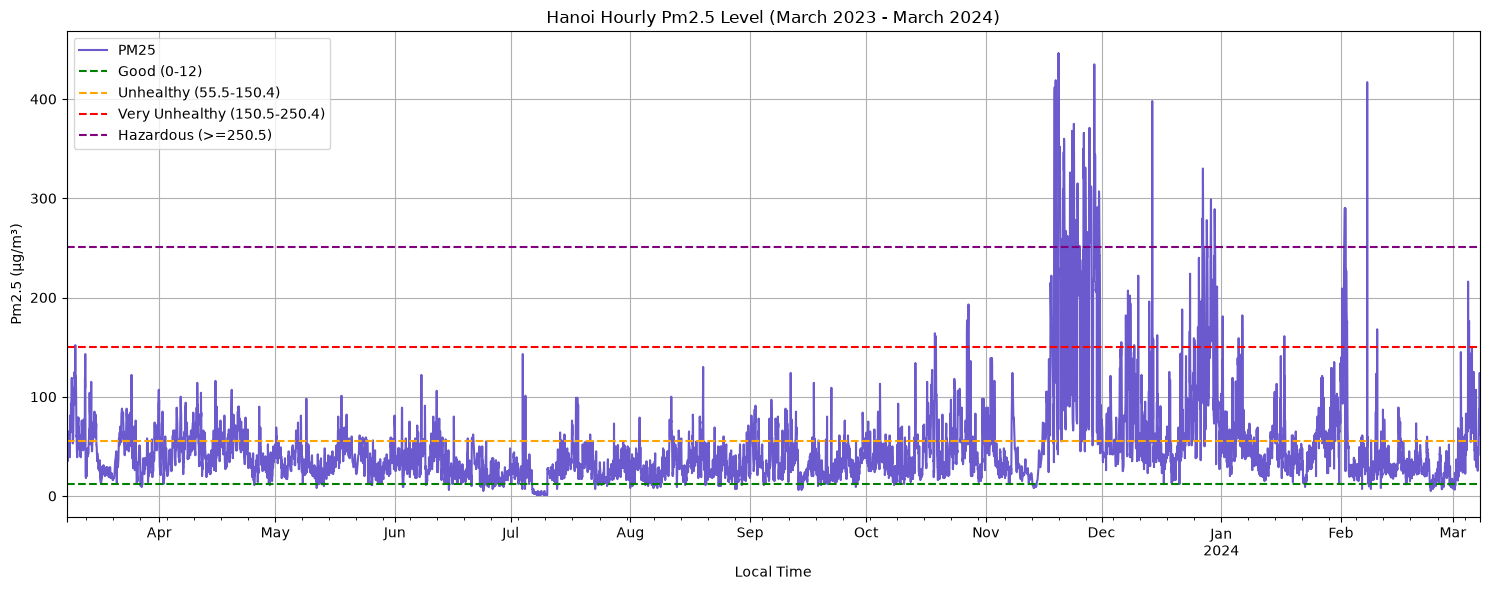

In [6]:
# Vẽ biểu đồ đường chuỗi thời gian PM2.5
plt.figure(figsize=(15, 6))
df['PM25'].plot(kind='line', color='slateblue')

# Thêm nhãn trục và tiêu đề
plt.xlabel('Local Time')
plt.ylabel('Pm2.5 (μg/m³)')
plt.title('Hanoi Hourly Pm2.5 Level (March 2023 - March 2024)')
# Thêm các đường ngang thể hiện ngưỡng mức độ ô nhiễm
plt.axhline(y=12, color='green', linestyle='--', label='Good (0-12)')
plt.axhline(y=55.5, color='orange', linestyle='--', label='Unhealthy (55.5-150.4)')
plt.axhline(y=150.5, color='red', linestyle='--', label='Very Unhealthy (150.5-250.4)')
plt.axhline(y=250.5, color='purple', linestyle='--', label='Hazardous (>=250.5)')
# Hiển thị chú thích
plt.legend()
# Hiển thị biểu đồ
plt.grid(True)
plt.tight_layout()
plt.show()


*Theo biểu đồ trên, biến động của nồng độ PM2.5 khá tương đồng với biến động của AQI. Hơn nữa, có rất ít giờ mà nồng độ PM2.5 nằm trong mức "Tốt".*

### 3.3.2. Các giờ có nồng độ PM2.5 cao nhất

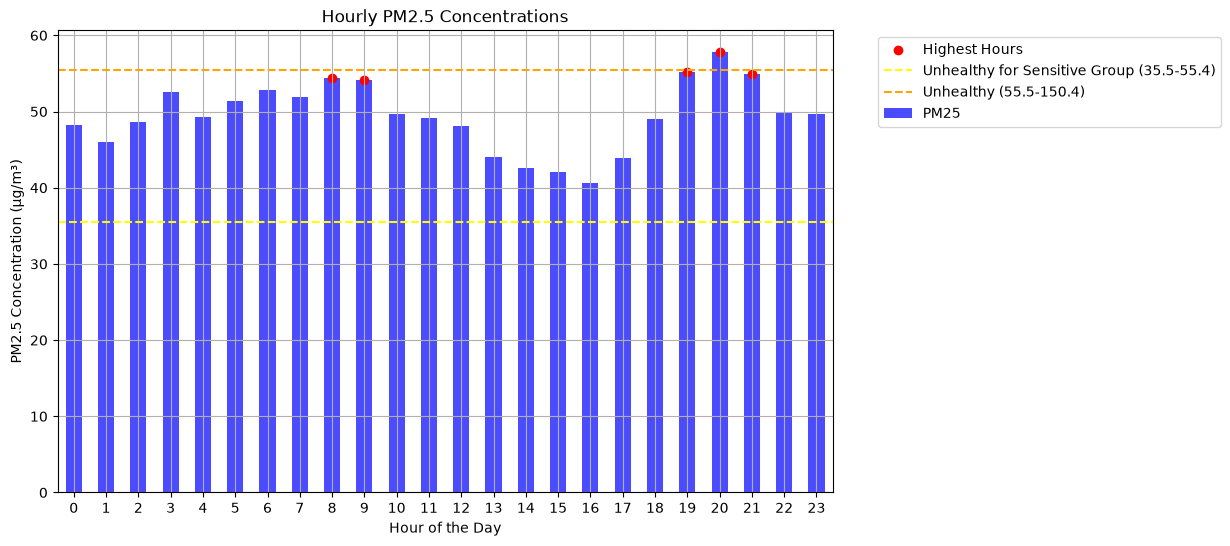

PM2.5 concentration at hour 8: 54.40
PM2.5 concentration at hour 9: 54.09
PM2.5 concentration at hour 19: 55.19
PM2.5 concentration at hour 20: 57.75
PM2.5 concentration at hour 21: 54.89


In [7]:
# Nhóm dữ liệu theo giờ và tính nồng độ PM2.5 trung bình của mỗi giờ
hourly_pm25 = df['PM25'].groupby(df.index.hour).mean()

# Tìm các giờ có nồng độ PM2.5 cao nhất
highest_hours = hourly_pm25.nlargest(5)  # Đổi số 5 thành số giờ cao nhất muốn hiển thị

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))
hourly_pm25.plot(kind='bar', color='blue', alpha=0.7)  # Vẽ nồng độ PM2.5 theo giờ
plt.scatter(highest_hours.index, highest_hours.values, color='red', label='Highest Hours')  # Đánh dấu các giờ cao nhất bằng chấm đỏ
plt.title('Hourly PM2.5 Concentrations')
plt.xlabel('Hour of the Day')
plt.ylabel('PM2.5 Concentration (μg/m³)')
plt.axhline(y=35.5, color='yellow', linestyle='--', label='Unhealthy for Sensitive Group (35.5-55.4)')
plt.axhline(y=55.5, color='orange', linestyle='--', label='Unhealthy (55.5-150.4)')

# Đưa chú thích ra góc trên bên trái, bên ngoài biểu đồ
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.grid(True)

# Giữ nhãn trục x nằm ngang
plt.xticks(rotation='horizontal')

plt.show()

# Danh sách các giờ cần xem
specific_hours = [8, 9, 19, 20, 21]

# In nồng độ PM2.5 tại các giờ cụ thể
for hour in specific_hours:
    pm25_concentration = hourly_pm25.loc[hour]
    print(f"PM2.5 concentration at hour {hour}: {pm25_concentration:.2f}")


*Để xác định các giờ cao điểm của nồng độ PM2.5 trong ngày, tôi nhóm dữ liệu theo giờ và tính nồng độ PM2.5 trung bình của mỗi giờ. Kết quả cho thấy tất cả các giờ đều có nồng độ PM2.5 ở mức "Không tốt cho nhóm nhạy cảm", và các giờ cao điểm là 8h, 9h, 19h, 20h và 21h. Những giờ này trùng với giờ cao điểm giao thông, cho thấy khí thải từ phương tiện giao thông đóng góp đáng kể vào ô nhiễm PM2.5. Đáng chú ý, nồng độ PM2.5 tích tụ dần trong ngày và đạt đỉnh cao nhất vào lúc 19h, 20h và 21h, với giá trị lần lượt là 55.19 μg/m³, 57.75 μg/m³ và 54.89 μg/m³.*

### 3.3.3. Nồng độ PM2.5 trung bình theo mùa

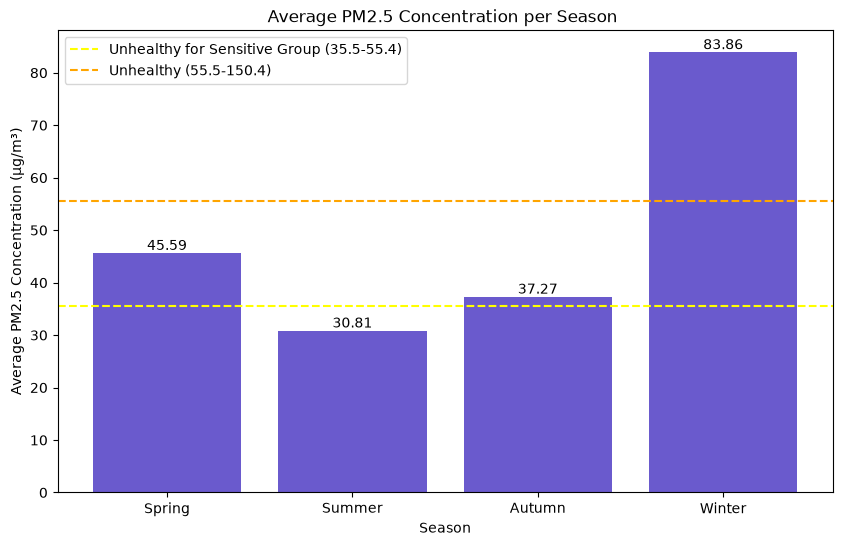

In [8]:
# Định nghĩa các mùa
seasons = {
    'Spring': [2, 3, 4],
    'Summer': [5, 6, 7],
    'Autumn': [8, 9, 10],
    'Winter': [11, 12, 1]
}

# Nhóm dữ liệu theo mùa và tính nồng độ PM2.5 trung bình của mỗi mùa
seasonal_pm25 = {}
for season, months in seasons.items():
    seasonal_pm25[season] = df.loc[df.index.month.isin(months), 'PM25'].mean()

# Vẽ nồng độ PM2.5 trung bình theo từng mùa
plt.figure(figsize=(10, 6))
bars = plt.bar(seasonal_pm25.keys(), seasonal_pm25.values(), color='slateblue')
plt.title('Average PM2.5 Concentration per Season ')
plt.xlabel('Season')
plt.ylabel('Average PM2.5 Concentration (μg/m³)')
plt.axhline(y=35.5, color='yellow', linestyle='--', label='Unhealthy for Sensitive Group (35.5-55.4)')
plt.axhline(y=55.5, color='orange', linestyle='--', label='Unhealthy (55.5-150.4)')
plt.legend()

# Ghi giá trị nồng độ PM2.5 trung bình của từng mùa lên đầu mỗi cột
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, round(height, 2),
             ha='center', va='bottom')

plt.show()

*Để xác định xu hướng PM2.5 theo mùa, tôi nhóm dữ liệu theo bốn mùa (Xuân: tháng 2, 3, 4; Hạ: tháng 5, 6, 7; Thu: tháng 8, 9, 10; Đông: tháng 11, 12, 1) và tính nồng độ PM2.5 trung bình của từng mùa. Kết quả cho thấy mùa đông có nồng độ PM2.5 trung bình cao nhất, ở mức 83.86 μg/m³, và là mùa duy nhất vượt ngưỡng "Có hại cho sức khỏe" (Unhealthy). Mùa xuân và mùa thu ở mức "Không tốt cho nhóm nhạy cảm", còn mùa hạ ở mức "Trung bình" (Moderate).*

## 3.4. Lượng mưa

### 3.4.1. Chuỗi thời gian lượng mưa theo giờ

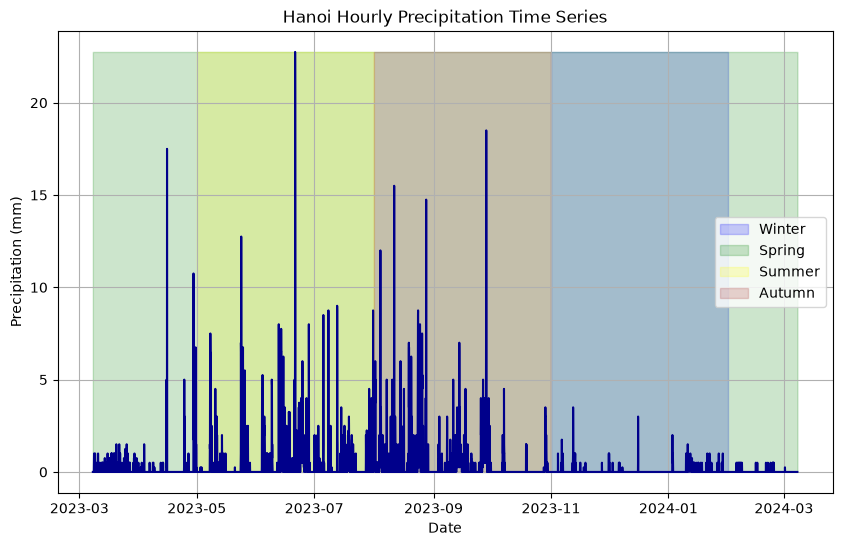

Annual Precipitation: 2408.25 mm


In [9]:
# Vẽ biến lượng mưa
plt.figure(figsize=(10, 6))

# Định nghĩa các mùa (theo mùa khí tượng: đông, xuân, hạ, thu)
winter_months = [11, 12, 1]
spring_months = [2, 3, 4]
summer_months = [5, 6, 7]
autumn_months = [8, 9, 10]

# Vẽ toàn bộ chuỗi thời gian lượng mưa
plt.plot(df.index, df['Precipitation'], color='darkblue')

# Tô màu vùng mùa đông
plt.fill_between(df.index[df.index.month.isin(winter_months)], df['Precipitation'].min(), df['Precipitation'].max(), color='blue', alpha=0.2, label='Winter')

# Tô màu vùng mùa xuân
plt.fill_between(df.index[df.index.month.isin(spring_months)], df['Precipitation'].min(), df['Precipitation'].max(), color='green', alpha=0.2, label='Spring')

# Tô màu vùng mùa hạ
plt.fill_between(df.index[df.index.month.isin(summer_months)], df['Precipitation'].min(), df['Precipitation'].max(), color='yellow', alpha=0.2, label='Summer')

# Tô màu vùng mùa thu
plt.fill_between(df.index[df.index.month.isin(autumn_months)], df['Precipitation'].min(), df['Precipitation'].max(), color='brown', alpha=0.2, label='Autumn')

# Đặt tiêu đề và nhãn trục
plt.title('Hanoi Hourly Precipitation Time Series')
plt.xlabel('Date')
plt.ylabel('Precipitation (mm)')

# Thêm chú thích
plt.legend()

# Hiển thị biểu đồ
plt.grid(True)
plt.show()

# Tính tổng lượng mưa của cả năm
annual_total_precipitation = df['Precipitation'].sum()

print("Annual Precipitation:", annual_total_precipitation, "mm")


### 3.4.2. Tổng lượng mưa theo mùa

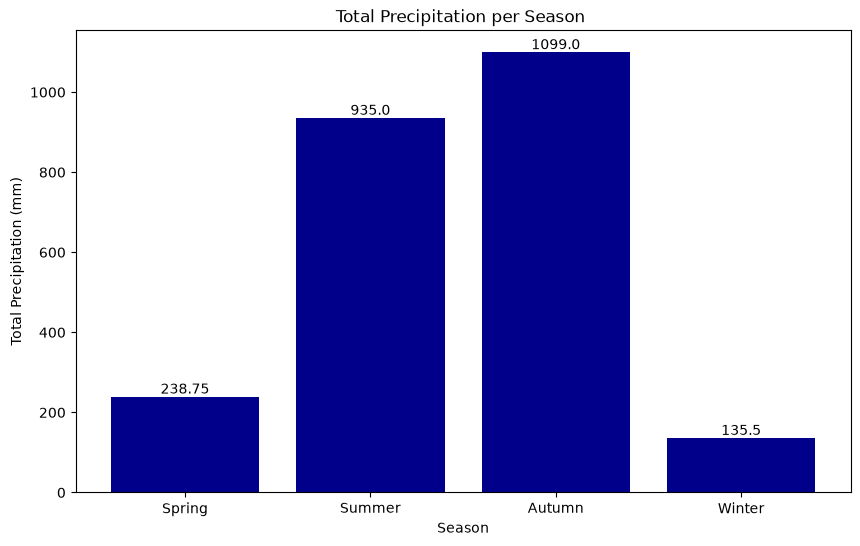

In [10]:
# Định nghĩa các mùa
seasons = {
    'Spring': [2, 3, 4],
    'Summer': [5, 6, 7],
    'Autumn': [8, 9, 10],
    'Winter': [11, 12, 1]
}

# Nhóm dữ liệu theo mùa và tính tổng lượng mưa của mỗi mùa
seasonal_precipitation = {}
for season, months in seasons.items():
    seasonal_precipitation[season] = df.loc[df.index.month.isin(months), 'Precipitation'].sum()

# Vẽ tổng lượng mưa theo từng mùa
plt.figure(figsize=(10, 6))
bars = plt.bar(seasonal_precipitation.keys(), seasonal_precipitation.values(), color='darkblue')
plt.title('Total Precipitation per Season ')
plt.xlabel('Season')
plt.ylabel('Total Precipitation (mm)')

# Ghi tổng lượng mưa của từng mùa lên đầu mỗi cột
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, round(height, 2),
             ha='center', va='bottom')

plt.show()

*Hà Nội có lượng mưa khá lớn trong năm qua, tổng cộng 2408.25 mm. Qua biểu đồ và số liệu lượng mưa theo mùa, có thể thấy mùa hạ và mùa thu mưa nhiều nhất, trong đó mùa thu là mùa mưa nhiều nhất. Ngược lại, mùa xuân thường có mưa phùn, còn mùa đông là mùa khô nhất.*

## 3.5. Áp suất

### 3.5.1. Chuỗi thời gian áp suất theo giờ

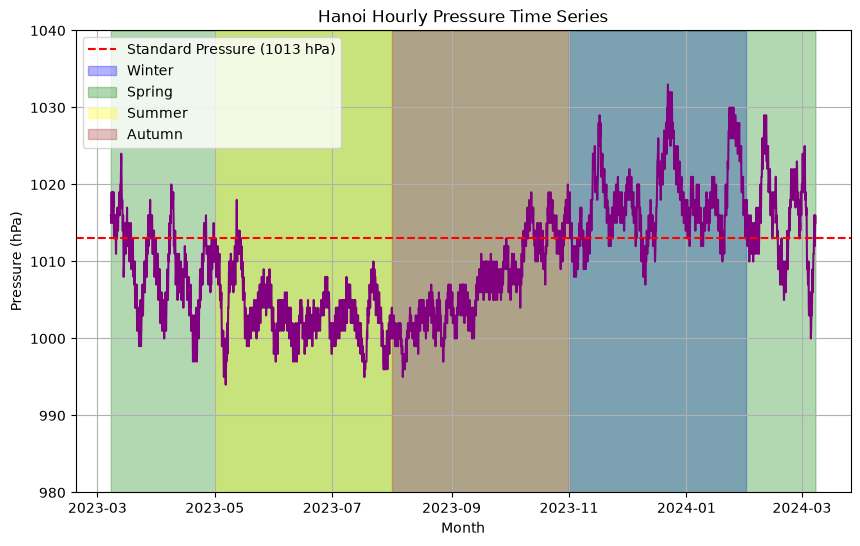

In [11]:
# Định nghĩa các mùa (theo mùa khí tượng: đông, xuân, hạ, thu)
winter_months = [11, 12, 1]
spring_months = [2, 3, 4]
summer_months = [5, 6, 7]
autumn_months = [8, 9, 10]

# Vẽ biến áp suất dưới dạng biểu đồ đường
plt.figure(figsize=(10, 6))  # Đặt kích thước biểu đồ
plt.plot(df.index, df['Pressure'], color='purple')  # Vẽ biểu đồ

# Thêm đường ngang tại 1013 hPa kèm nhãn
plt.axhline(y=1013, color='red', linestyle='--', label='Standard Pressure (1013 hPa)')

# Tô màu vùng mùa đông
plt.fill_between(df.index[df.index.month.isin(winter_months)], 980, 1040, color='blue', alpha=0.3, label='Winter')

# Tô màu vùng mùa xuân
plt.fill_between(df.index[df.index.month.isin(spring_months)], 980, 1040, color='green', alpha=0.3, label='Spring')

# Tô màu vùng mùa hạ
plt.fill_between(df.index[df.index.month.isin(summer_months)], 980, 1040, color='yellow', alpha=0.3, label='Summer')

# Tô màu vùng mùa thu
plt.fill_between(df.index[df.index.month.isin(autumn_months)], 980, 1040, color='brown', alpha=0.3, label='Autumn')

plt.title('Hanoi Hourly Pressure Time Series')  # Đặt tiêu đề
plt.xlabel('Month')  # Đặt nhãn trục x
plt.ylabel('Pressure (hPa)')  # Đặt nhãn trục y
plt.ylim(980, 1040)  # Đặt giới hạn trục y
plt.grid(True)  # Thêm lưới
plt.legend()  # Hiển thị chú thích
plt.show()  # Hiển thị biểu đồ

### 3.5.2. Áp suất trung bình theo mùa

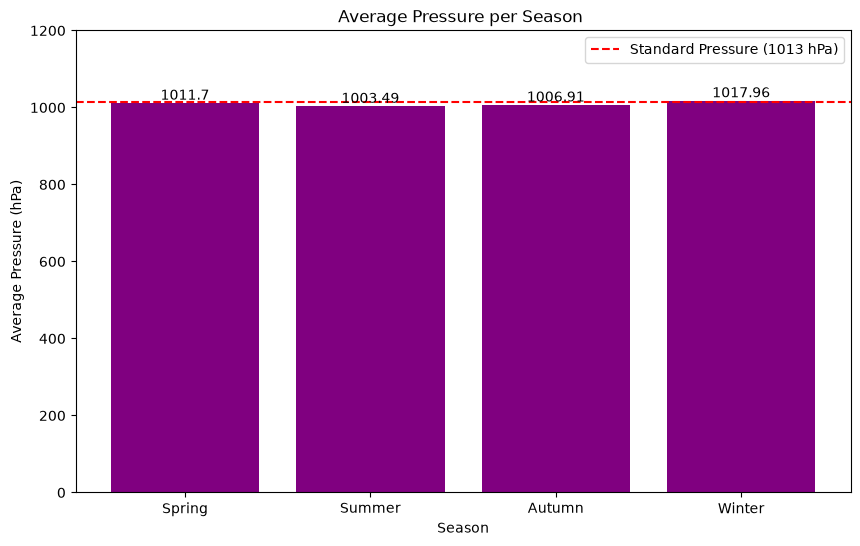

In [12]:
# Định nghĩa các mùa
seasons = {
    'Spring': [2, 3, 4],
    'Summer': [5, 6, 7],
    'Autumn': [8, 9, 10],
    'Winter': [11, 12, 1]
}

# Nhóm dữ liệu theo mùa và tính áp suất trung bình của mỗi mùa
seasonal_humid = {}
for season, months in seasons.items():
    seasonal_humid[season] = df.loc[df.index.month.isin(months), 'Pressure'].mean()

# Vẽ áp suất trung bình theo từng mùa
plt.figure(figsize=(10, 6))
bars = plt.bar(seasonal_humid.keys(), seasonal_humid.values(), color='purple')
plt.axhline(y=1013, color='red', linestyle='--', label='Standard Pressure (1013 hPa)')
plt.title('Average Pressure per Season ')
plt.xlabel('Season')
plt.ylabel('Average Pressure (hPa)')
plt.ylim(0, 1200)  # Đặt giới hạn trục y

# Ghi giá trị áp suất trung bình của từng mùa lên đầu mỗi cột
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, round(height, 2),
             ha='center', va='bottom')
plt.legend()  # Hiển thị chú thích
plt.show()

*Qua các biểu đồ trên, áp suất của Hà Nội vào mùa hạ và mùa thu thấp hơn đáng kể so với mức tiêu chuẩn. Theo [National Geographic](https://education.nationalgeographic.org/resource/atmospheric-pressure/), hiện tượng này thường đi kèm các hệ thống áp thấp, vốn mang theo mây, gió mạnh hơn và mưa. Điều này giải thích lượng mưa lớn quan sát được trong các mùa này. Ngược lại, mùa đông có áp suất khí quyển cao nhất, khiến không khí bị tù đọng. Theo giải thích của [University Corporation for Atmospheric Research](https://scied.ucar.edu/learning-zone/air-quality/how-weather-affects-air-quality), không khí tù đọng có thể giữ lại các chất ô nhiễm từ khí thải xe cộ và nhà máy trong bầu khí quyển của thành phố, dẫn tới nồng độ PM2.5 tăng cao vào mùa này. Trong khi đó, áp suất mùa xuân dao động quanh mức tiêu chuẩn, cho thấy điều kiện khí quyển tương đối ổn định.*

## 3.6. Độ ẩm

### 3.6.1. Chuỗi thời gian độ ẩm theo giờ

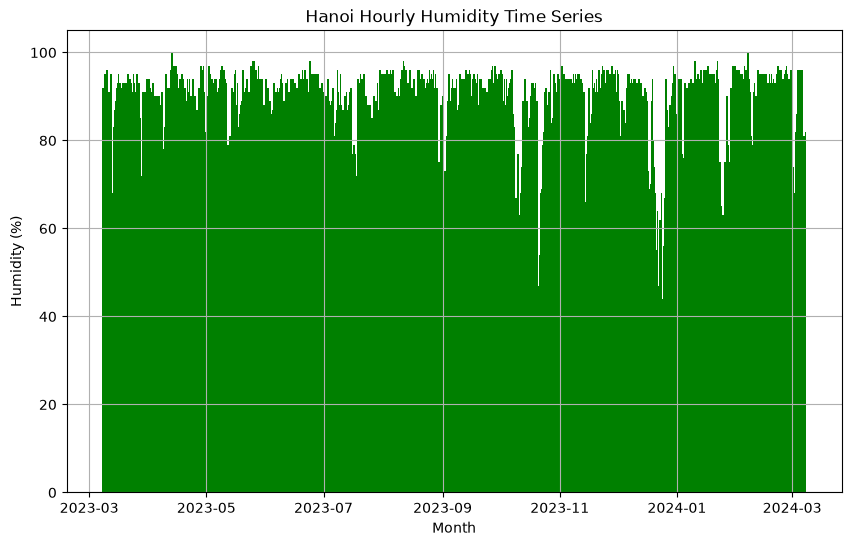

Average Annual Relative Humidity: 78.04 %


In [13]:
# Vẽ biến độ ẩm
plt.figure(figsize=(10, 6))  # Đặt kích thước biểu đồ
plt.bar(df.index, df['Relative Humidity'], color='green', linestyle='-')  # Vẽ biểu đồ
plt.title('Hanoi Hourly Humidity Time Series')  # Đặt tiêu đề
plt.xlabel('Month')  # Đặt nhãn trục x
plt.ylabel('Humidity (%)')  # Đặt nhãn trục y
plt.grid(True)  # Thêm lưới
plt.show()  # Hiển thị biểu đồ

# Tính độ ẩm tương đối trung bình cả năm
average_annual_rh = df["Relative Humidity"].mean()

print("Average Annual Relative Humidity:", round(average_annual_rh, 2), '%')

### 3.6.2. Độ ẩm trung bình theo mùa

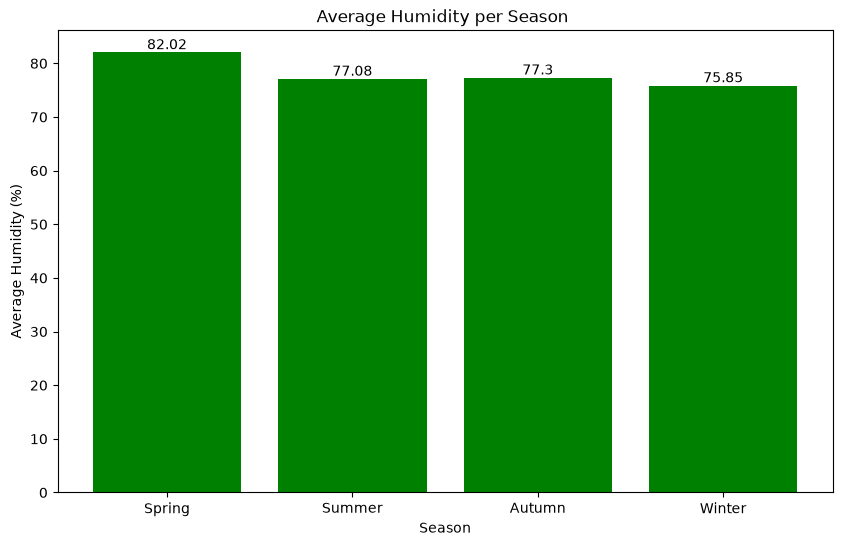

In [14]:
# Định nghĩa các mùa
seasons = {
    'Spring': [2, 3, 4],
    'Summer': [5, 6, 7],
    'Autumn': [8, 9, 10],
    'Winter': [11, 12, 1]
}

# Nhóm dữ liệu theo mùa và tính độ ẩm trung bình của mỗi mùa
seasonal_humid = {}
for season, months in seasons.items():
    seasonal_humid[season] = df.loc[df.index.month.isin(months), 'Relative Humidity'].mean()

# Vẽ độ ẩm trung bình theo từng mùa
plt.figure(figsize=(10, 6))
bars = plt.bar(seasonal_humid.keys(), seasonal_humid.values(), color='green')
plt.title('Average Humidity per Season ')
plt.xlabel('Season')
plt.ylabel('Average Humidity (%)')

# Ghi giá trị độ ẩm trung bình của từng mùa lên đầu mỗi cột
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, round(height, 2),
             ha='center', va='bottom')

plt.show()

*Hà Nội có độ ẩm trung bình 78.05%, thuộc nhóm thành phố ẩm nhất châu Á. Độ ẩm cao nhất vào mùa xuân, trùng với thời điểm thường có mưa phùn, trong khi các mùa còn lại có độ ẩm xấp xỉ nhau.*

*Trong bài viết ["Những người 'chia tay' Hà Nội vì nồm ẩm"](https://www.vietnam.vn/en/nhung-nguoi-chia-tay-ha-noi-vi-nom-am/) của VnExpress, mùa xuân ở Hà Nội mang lại nhiều khó chịu cho người dân, thường gây ốm đau và khiến sinh hoạt trở nên bất tiện. Khi nhiệt độ tăng cùng với độ ẩm, nhà cửa "đổ mồ hôi", quần áo luôn ẩm và bốc mùi khó chịu. Bài viết kể câu chuyện cảm động về một người Hà Nội buộc phải rời quê hương vì chất lượng không khí và thời tiết khắc nghiệt. Những khó khăn và ảnh hưởng sức khỏe mà gia đình chị gặp phải, cũng là điều tôi đồng cảm khi viết những dòng này, được khắc họa rất rõ trong bài. Bạn có thể đọc bài viết để hiểu thêm về câu chuyện của chị.*

## 3.7. Nhiệt độ

### 3.7.1. Chuỗi thời gian nhiệt độ theo giờ

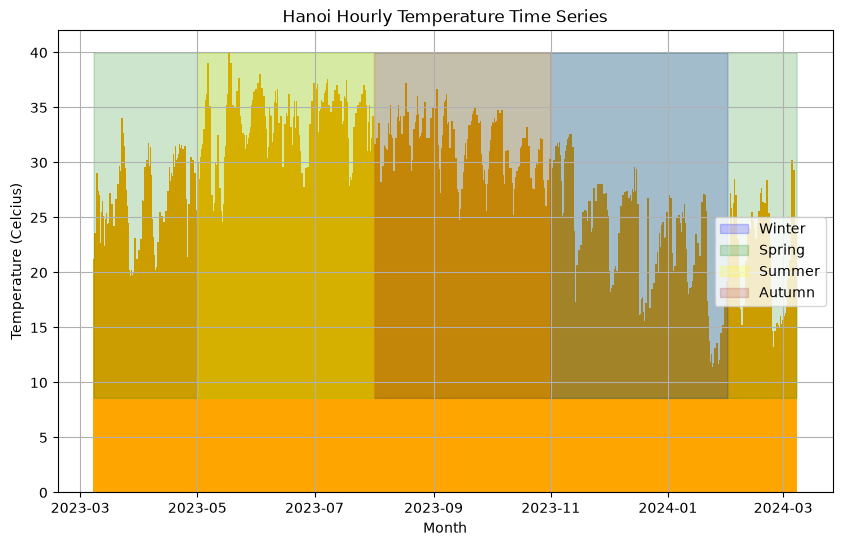

Average Annual Temperature: 25.28 ℃ 



In [15]:
# Định nghĩa các mùa (theo mùa khí tượng: đông, xuân, hạ, thu)
winter_months = [11, 12, 1]
spring_months = [2, 3, 4]
summer_months = [5, 6, 7]
autumn_months = [8, 9, 10]

# Vẽ biến nhiệt độ
plt.figure(figsize=(10, 6))

# Vẽ toàn bộ chuỗi thời gian nhiệt độ
plt.bar(df.index, df['Temperature'], color='orange', linestyle='-')

# Tô màu vùng mùa đông
plt.fill_between(df.index[df.index.month.isin(winter_months)], df['Temperature'].min(), df['Temperature'].max(), color='blue', alpha=0.2, label='Winter')

# Tô màu vùng mùa xuân
plt.fill_between(df.index[df.index.month.isin(spring_months)], df['Temperature'].min(), df['Temperature'].max(), color='green', alpha=0.2, label='Spring')

# Tô màu vùng mùa hạ
plt.fill_between(df.index[df.index.month.isin(summer_months)], df['Temperature'].min(), df['Temperature'].max(), color='yellow', alpha=0.2, label='Summer')

# Tô màu vùng mùa thu
plt.fill_between(df.index[df.index.month.isin(autumn_months)], df['Temperature'].min(), df['Temperature'].max(), color='brown', alpha=0.2, label='Autumn')

# Đặt tiêu đề và nhãn trục
plt.title('Hanoi Hourly Temperature Time Series')
plt.xlabel('Month')
plt.ylabel('Temperature (Celcius)')

# Thêm chú thích
plt.legend()

# Hiển thị biểu đồ
plt.grid(True)
plt.show()

average_annual_temperature = df['Temperature'].mean()

# In nhiệt độ trung bình cả năm
print("Average Annual Temperature:", round(average_annual_temperature, 2), "℃ \n")

*Theo biểu đồ nhiệt độ theo giờ, có rất nhiều đỉnh, cho thấy nhiệt độ thường đạt cao nhất vào giữa trưa rồi giảm dần về nửa đêm mỗi ngày.*

### 3.7.2. Nhiệt độ trung bình theo mùa

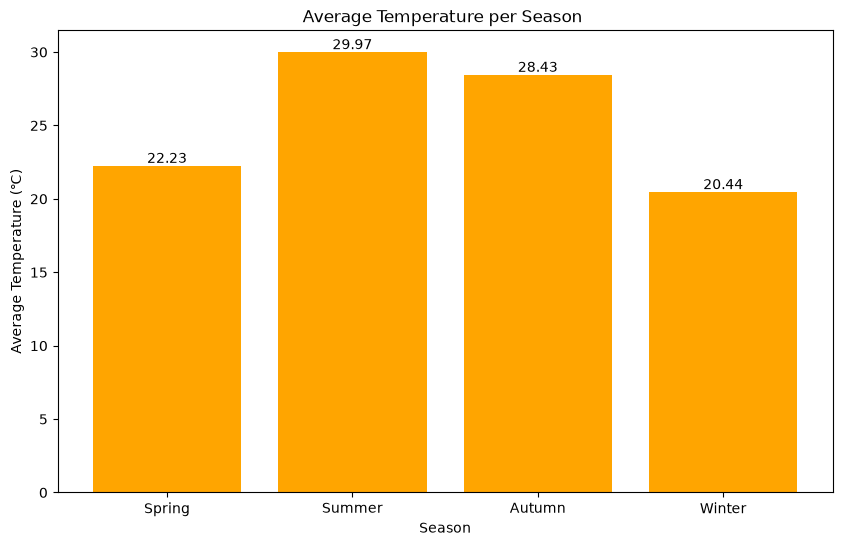

In [16]:
# Định nghĩa các mùa
seasons = {
    'Spring': [2, 3, 4],
    'Summer': [5, 6, 7],
    'Autumn': [8, 9, 10],
    'Winter': [11, 12, 1]
}

# Nhóm dữ liệu theo mùa và tính nhiệt độ trung bình của mỗi mùa
seasonal_temp = {}
for season, months in seasons.items():
    seasonal_temp[season] = df.loc[df.index.month.isin(months), 'Temperature'].mean()

# Vẽ nhiệt độ trung bình theo từng mùa
plt.figure(figsize=(10, 6))
bars = plt.bar(seasonal_temp.keys(), seasonal_temp.values(), color='orange')
plt.title('Average Temperature per Season ')
plt.xlabel('Season')
plt.ylabel('Average Temperature (℃)')

# Ghi giá trị nhiệt độ trung bình của từng mùa lên đầu mỗi cột
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, round(height, 2),
             ha='center', va='bottom')

plt.show()

*Đáng chú ý, nhiệt độ trung bình mùa hạ và mùa thu đều trên 28℃, cho thấy thời tiết rất nóng trong các mùa này. Ngược lại, nhiệt độ trung bình mùa xuân và mùa đông chỉ chênh nhau 1.79℃.*

## 3.8. Tốc độ gió

### 3.8.1. Chuỗi thời gian tốc độ gió theo giờ

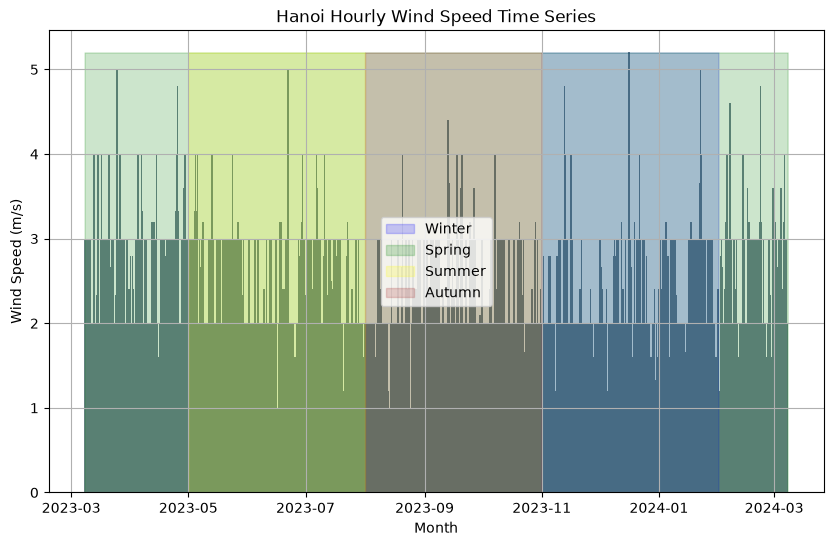

Average Annual Wind Speed: 1.61 m/s



In [17]:
# Định nghĩa các mùa (theo mùa khí tượng: đông, xuân, hạ, thu)
winter_months = [11, 12, 1]
spring_months = [2, 3, 4]
summer_months = [5, 6, 7]
autumn_months = [8, 9, 10]

# Vẽ biến tốc độ gió
plt.figure(figsize=(10, 6))

# Vẽ toàn bộ chuỗi thời gian tốc độ gió
plt.bar(df.index, df['Wind Speed'], color='slategray', linestyle='-')

# Tô màu vùng mùa đông
plt.fill_between(df.index[df.index.month.isin(winter_months)], df['Wind Speed'].min(), df['Wind Speed'].max(), color='blue', alpha=0.2, label='Winter')

# Tô màu vùng mùa xuân
plt.fill_between(df.index[df.index.month.isin(spring_months)], df['Wind Speed'].min(), df['Wind Speed'].max(), color='green', alpha=0.2, label='Spring')

# Tô màu vùng mùa hạ
plt.fill_between(df.index[df.index.month.isin(summer_months)], df['Wind Speed'].min(), df['Wind Speed'].max(), color='yellow', alpha=0.2, label='Summer')

# Tô màu vùng mùa thu
plt.fill_between(df.index[df.index.month.isin(autumn_months)], df['Wind Speed'].min(), df['Wind Speed'].max(), color='brown', alpha=0.2, label='Autumn')

# Đặt tiêu đề và nhãn trục
plt.title('Hanoi Hourly Wind Speed Time Series')
plt.xlabel('Month')
plt.ylabel('Wind Speed (m/s)')

# Thêm chú thích
plt.legend()

# Hiển thị biểu đồ
plt.grid(True)
plt.show()

# Tính tốc độ gió trung bình cả năm
average_annual_wind_speed = df['Wind Speed'].mean()

# In tốc độ gió trung bình cả năm
print("Average Annual Wind Speed:", round(average_annual_wind_speed, 2), "m/s\n")

### 3.8.2. Tốc độ gió trung bình theo mùa

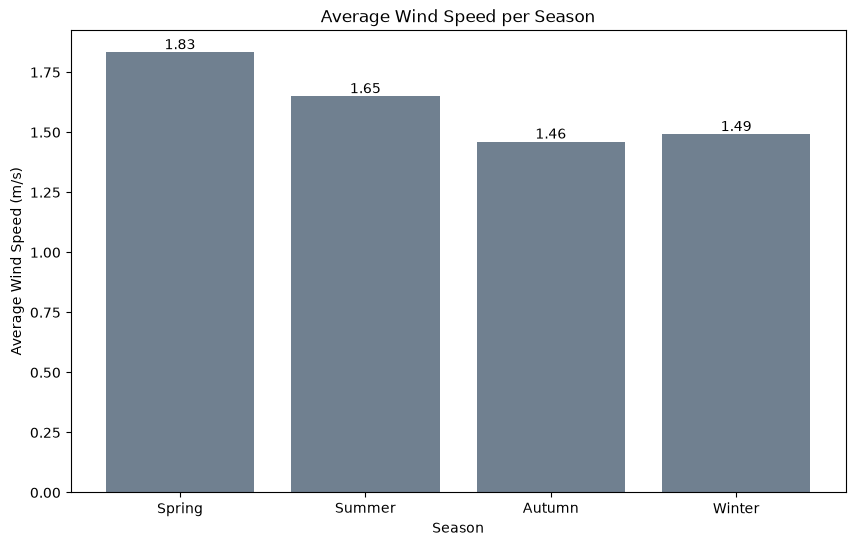

In [18]:
# Định nghĩa các mùa
seasons = {
    'Spring': [2, 3, 4],
    'Summer': [5, 6, 7],
    'Autumn': [8, 9, 10],
    'Winter': [11, 12, 1]
}

# Nhóm dữ liệu theo mùa và tính tốc độ gió trung bình của mỗi mùa
seasonal_wind_speed = {}
for season, months in seasons.items():
    seasonal_wind_speed[season] = df.loc[df.index.month.isin(months), 'Wind Speed'].mean()

# Vẽ tốc độ gió trung bình theo từng mùa
plt.figure(figsize=(10, 6))
bars = plt.bar(seasonal_wind_speed.keys(), seasonal_wind_speed.values(), color='slategray')
plt.title('Average Wind Speed per Season')
plt.xlabel('Season')
plt.ylabel('Average Wind Speed (m/s)')

# Ghi giá trị tốc độ gió trung bình của từng mùa lên đầu mỗi cột
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, round(height, 2),
             ha='center', va='bottom')

plt.show()


*Nhìn chung, Hà Nội có tốc độ gió tương đối thấp, trung bình cả năm là 1.61 m/s. Trong năm qua, mùa xuân có tốc độ gió trung bình cao nhất, có thể do ảnh hưởng của [gió mùa Đông Bắc](https://www.vietnamdrive.com/monsoon-seasons/). Mùa hạ đứng thứ hai, có thể do thường xuyên có mưa rào. Điều thú vị là mùa thu và mùa đông có tốc độ gió tương đương nhau.*

# IV. Ảnh hưởng của điều kiện thời tiết tới chất lượng không khí

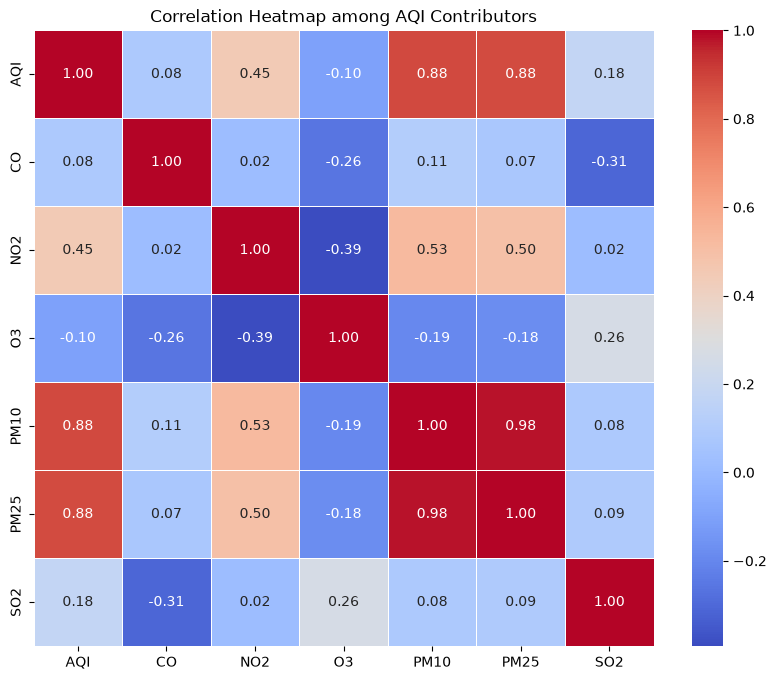

In [19]:
# Chọn các cột liên quan
corr_columns = ['AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2']

# Tính ma trận tương quan
correlation_matrix = df[corr_columns].corr()

# Vẽ heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap among AQI Contributors')
plt.show()

*Theo heatmap tương quan, PM2.5 và PM10 có tương quan cao với AQI, cho thấy PM2.5 và PM10 là các yếu tố đóng góp chính vào AQI. Hơn nữa, theo [VnExpress](https://e.vnexpress.net/news/environment/hanoi-s-air-quality-dropping-over-large-scales-4719205.html), ô nhiễm không khí ở Hà Nội chủ yếu do bụi PM2.5. Vì vậy, tôi chọn PM2.5 làm biến đo lường chất lượng không khí.*

*Về điều kiện thời tiết, tôi chọn lượng mưa, áp suất, độ ẩm, nhiệt độ và tốc độ gió làm các biến thời tiết.*

## 4.1. Lượng mưa có ảnh hưởng tới chất lượng không khí không?

Để đánh giá đầy đủ ảnh hưởng của mưa tới chất lượng không khí, tôi sẽ xem xét cả thời gian mưa và lượng mưa tác động thế nào tới nồng độ PM2.5.

Đầu tiên, tôi tính số giờ mưa liên tục và lưu vào một cột mới tên 'Accumulated Hours of Rain'. Cột này đếm số giờ liên tiếp có lượng mưa khác 0, và được đặt lại về 0 mỗi khi tạnh mưa.

### 4.1.1. Tính số giờ mưa tích lũy

In [20]:
# Khởi tạo biến lưu số giờ mưa liên tục (tích lũy)
accumulated_hours_of_rain = 0

# Tạo danh sách rỗng để lưu số giờ mưa tích lũy của từng dòng
accumulated_hours_list = []

# Duyệt qua từng dòng trong DataFrame
for precipitation in df['Precipitation']:
    # Nếu giờ hiện tại có mưa
    if precipitation > 0:
        # Tăng số giờ mưa tích lũy thêm 1
        accumulated_hours_of_rain += 1
    else:
        # Nếu không mưa thì đặt lại số giờ tích lũy về 0
        accumulated_hours_of_rain = 0
    
    # Thêm số giờ mưa tích lũy vào danh sách
    accumulated_hours_list.append(accumulated_hours_of_rain)

# Thêm danh sách vừa tạo thành một cột mới trong DataFrame
df['Accumulated Hours of Rain'] = accumulated_hours_list

df.head()

,UTC Time,City,Country Code,Timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed,Accumulated Hours of Rain
Local Time,,,,,,,,,,,,,,,,,,,
2023-03-08 00:00:00,2023-03-07T17:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,131,170.6,29.3,53.3,58.8,47.0,67.3,91,0.0,1016,86,21.2,0.0,2.00,0
2023-03-08 01:00:00,2023-03-07T18:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,158.7,25.0,54.0,56.3,45.0,65.0,100,0.0,1016,89,21.1,0.0,2.00,0
2023-03-08 02:00:00,2023-03-07T19:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,150.2,21.7,55.0,52.5,42.0,65.7,100,0.0,1016,90,20.9,0.0,1.66,0
2023-03-08 03:00:00,2023-03-07T20:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,141.6,18.3,56.0,56.3,45.0,66.3,100,0.0,1016,91,20.7,0.0,1.33,0
2023-03-08 04:00:00,2023-03-07T21:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,133.1,15.0,57.0,52.5,42.0,67.0,100,0.0,1015,92,20.5,0.0,1.00,0


In [21]:
# Xem thống kê mô tả của cột 'Accumulated Hours of Rain'
print(df['Accumulated Hours of Rain'].describe())

count    8785.000000
mean        1.534092
std         5.691664
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        67.000000
Name: Accumulated Hours of Rain, dtype: float64


*Qua thống kê mô tả của cột 'Accumulated Hours of Rain', có thể thấy có lúc mưa liên tục khoảng 67 giờ, tức gần ba ngày. Mưa kéo dài như vậy trong thời gian ngắn cho thấy lượng mưa rất lớn trong những ngày đó.*

### 4.1.2. Mối quan hệ giữa số giờ mưa và nồng độ PM2.5

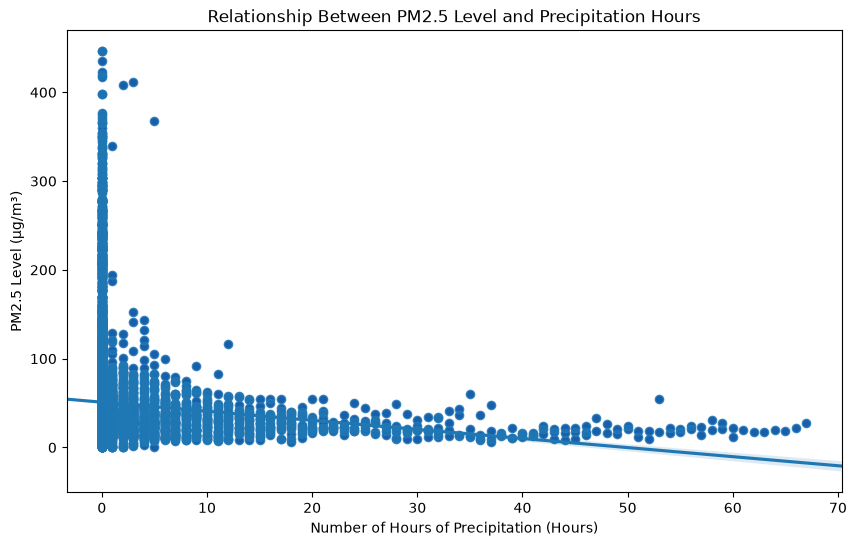

Correlation Coefficient: -0.12


In [22]:
# Biểu đồ phân tán
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Accumulated Hours of Rain', y='PM25', color='darkblue')

# Vẽ đường hồi quy
sns.regplot(data=df, x='Accumulated Hours of Rain', y='PM25', truncate=False)

# Tính hệ số tương quan
correlation_coefficient = df['Accumulated Hours of Rain'].corr(df['PM25'])

# Thêm tiêu đề và nhãn trục
plt.title('Relationship Between PM2.5 Level and Precipitation Hours')
plt.xlabel('Number of Hours of Precipitation (Hours)')
plt.ylabel('PM2.5 Level (μg/m³)')

plt.show()

# In hệ số tương quan
print(f"Correlation Coefficient: {correlation_coefficient:.2f}")


**Nhận xét:** *Biểu đồ cho thấy hệ số tương quan âm -0.12, tức tương quan rất yếu, có thể coi là không đáng kể. Tuy nhiên, khi xem xét kỹ xu hướng và quy luật, có thể thấy mưa càng nhiều giờ thì PM2.5 càng thấp. Do đó, có thể suy ra rằng khi thời gian mưa tăng lên, nồng độ PM2.5 có xu hướng giảm.*

### 4.1.3. Mối quan hệ giữa lượng mưa và nồng độ PM2.5

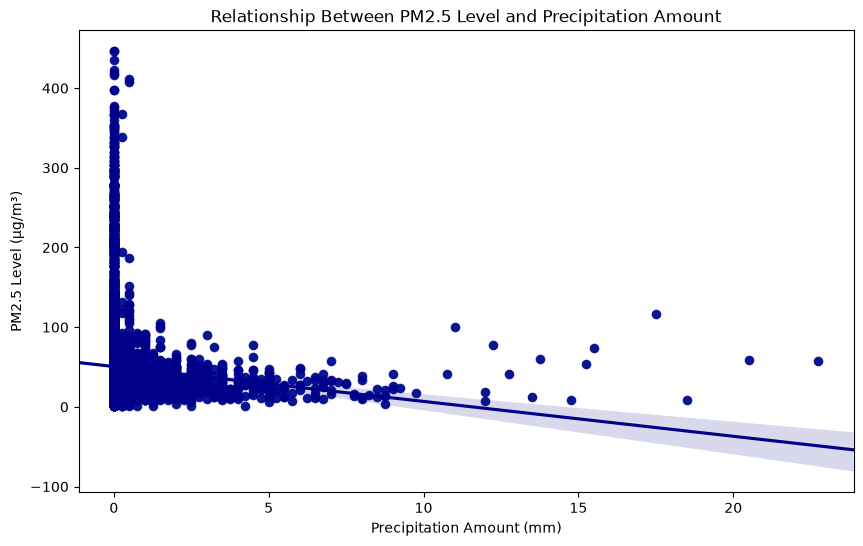

Correlation Coefficient: -0.09


In [23]:
# Biểu đồ phân tán
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Precipitation', y='PM25')

# Vẽ đường hồi quy
sns.regplot(data=df, x='Precipitation', y='PM25', truncate= False, color='darkblue')

# Tính hệ số tương quan
correlation_coefficient = df['Precipitation'].corr(df['PM25'])

# Thêm tiêu đề và nhãn trục
plt.title('Relationship Between PM2.5 Level and Precipitation Amount')
plt.xlabel('Precipitation Amount (mm)')
plt.ylabel('PM2.5 Level (μg/m³)')

plt.show()

# In hệ số tương quan
print(f"Correlation Coefficient: {correlation_coefficient:.2f}")


**Nhận xét:** *Hệ số tương quan giữa lượng mưa và PM2.5 gần bằng 0, nghĩa là không có mối quan hệ tuyến tính giữa hai biến. Khi tìm quy luật, có thể thấy ở những thời điểm lượng mưa lớn thì nồng độ PM2.5 thường thấp. Có thể nói rằng mưa càng to thì nồng độ PM2.5 càng thấp.*

## 4.2. Áp suất có ảnh hưởng tới chất lượng không khí không?

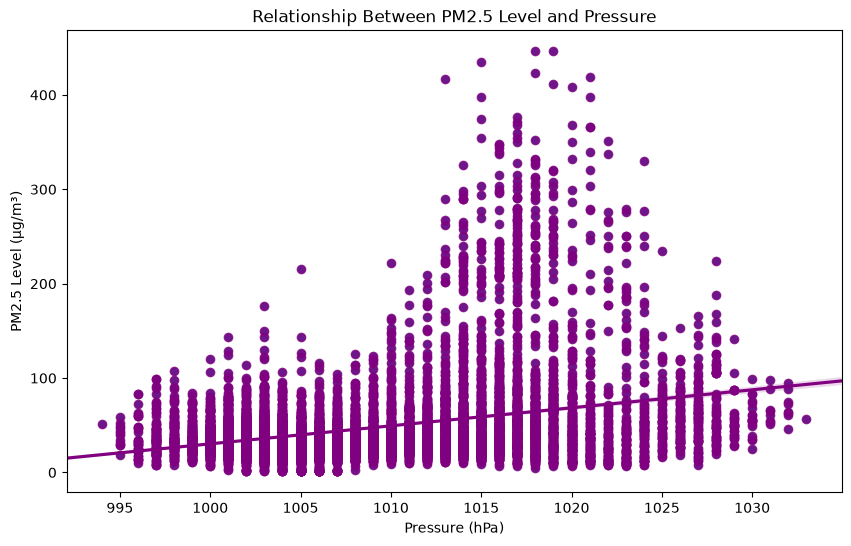

Correlation Coefficient: 0.30


In [24]:
# Biểu đồ phân tán
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Pressure', y='PM25')

# Vẽ đường hồi quy
sns.regplot(data=df, x='Pressure', y='PM25', truncate= False, color='purple')

# Tính hệ số tương quan
correlation_coefficient = df['Pressure'].corr(df['PM25'])

# Thêm tiêu đề và nhãn trục
plt.title('Relationship Between PM2.5 Level and Pressure')
plt.xlabel('Pressure (hPa)')
plt.ylabel('PM2.5 Level (μg/m³)')

plt.show()

# In hệ số tương quan
print(f"Correlation Coefficient: {correlation_coefficient:.2f}")

**Nhận xét:** *Hệ số tương quan giữa áp suất khí quyển và nồng độ PM2.5 là 0.3, cho thấy tương quan ở mức vừa phải. Rõ ràng là áp suất càng cao thì nồng độ PM2.5 càng cao. Theo giải thích của [University Corporation for Atmospheric Research](https://scied.ucar.edu/learning-zone/air-quality/how-weather-affects-air-quality), hệ thống áp thấp mang lại thời tiết ẩm ướt và nhiều gió. Một cơn mưa có thể rửa trôi chất ô nhiễm khỏi khí quyển hoặc đẩy chúng sang khu vực khác, giúp bầu trời trong lành. Ngược lại, hệ thống áp cao có thể làm không khí tù đọng, khiến các chất ô nhiễm như khí thải xe cộ và nhà máy tích tụ lại khi không khí ngừng lưu chuyển.*

## 4.3. Độ ẩm có ảnh hưởng tới chất lượng không khí không?

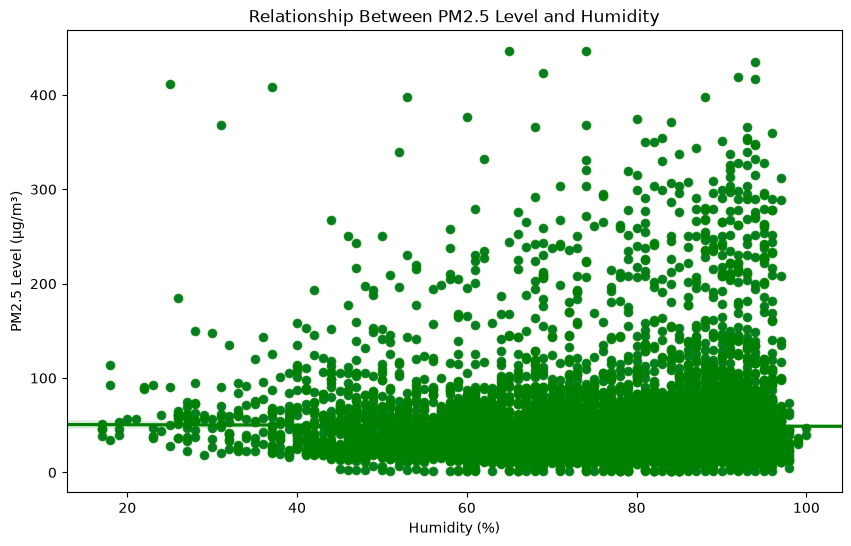

Correlation Coefficient: -0.01


In [25]:
# Biểu đồ phân tán
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Relative Humidity', y='PM25')

# Vẽ đường hồi quy
sns.regplot(data=df, x='Relative Humidity', y='PM25', truncate= False, color='green')

# Tính hệ số tương quan
correlation_coefficient = df['Relative Humidity'].corr(df['PM25'])

# Thêm tiêu đề và nhãn trục
plt.title('Relationship Between PM2.5 Level and Humidity')
plt.xlabel('Humidity (%)')
plt.ylabel('PM2.5 Level (μg/m³)')

plt.show()

# In hệ số tương quan
print(f"Correlation Coefficient: {correlation_coefficient:.2f}")

**Nhận xét:** *Hệ số tương quan giữa độ ẩm và nồng độ PM2.5 gần bằng 0, cho thấy không có mối quan hệ đáng kể. Biểu đồ phân tán cũng không thể hiện quy luật rõ ràng nào, cho thấy độ ẩm có thể không phải là yếu tố quan trọng ảnh hưởng tới nồng độ PM2.5.*

## 4.4. Nhiệt độ có ảnh hưởng tới chất lượng không khí không?

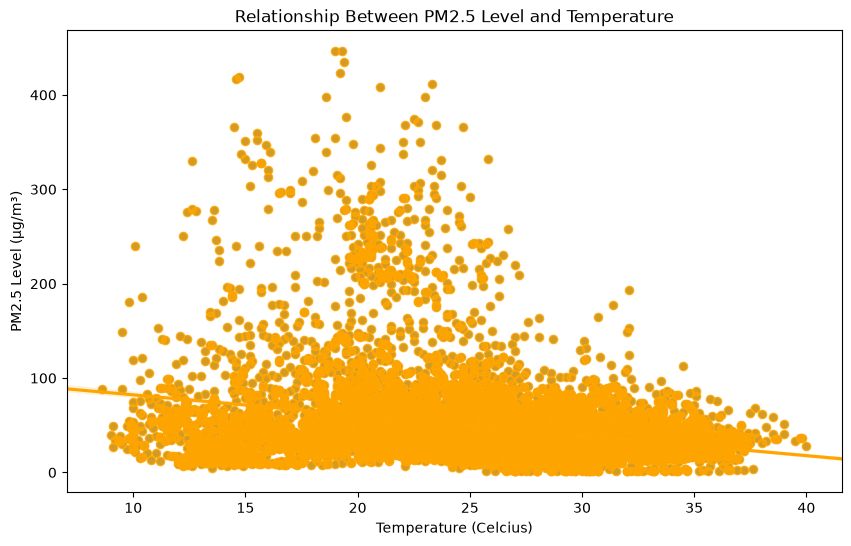

Correlation Coefficient: -0.25


In [26]:
# Biểu đồ phân tán
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Temperature', y='PM25')

# Vẽ đường hồi quy
sns.regplot(data=df, x='Temperature', y='PM25', truncate= False, color='orange')

# Tính hệ số tương quan
correlation_coefficient = df['Temperature'].corr(df['PM25'])

# Thêm tiêu đề và nhãn trục
plt.title('Relationship Between PM2.5 Level and Temperature')
plt.xlabel('Temperature (Celcius)')
plt.ylabel('PM2.5 Level (μg/m³)')

plt.show()

# In hệ số tương quan
print(f"Correlation Coefficient: {correlation_coefficient:.2f}")

**Nhận xét:** *Biểu đồ cho thấy hệ số tương quan âm -0.25, tức tương quan yếu giữa nhiệt độ và chỉ số PM2.5. Tuy nhiên, khi xem xét kỹ xu hướng và quy luật, có thể thấy trời càng lạnh thì nồng độ PM2.5 càng cao.*

*[University Corporation for Atmospheric Research](https://scied.ucar.edu/learning-zone/air-quality/how-weather-affects-air-quality) giải thích rằng vào mùa đông, lớp không khí ấm phía trên hoạt động như một chiếc nắp, giữ không khí lạnh ở sát mặt đất. Điều này tạo ra hiện tượng nghịch nhiệt – khi lớp không khí ấm phía trên giữ không khí lạnh và chất ô nhiễm ở gần mặt đất. Hình minh họa dưới đây thể hiện khá chính xác đặc điểm địa hình của Hà Nội với các dãy núi bao quanh. Địa hình tự nhiên này cản trở sự phát tán của ô nhiễm không khí, khiến chất ô nhiễm tích tụ trong thành phố.*
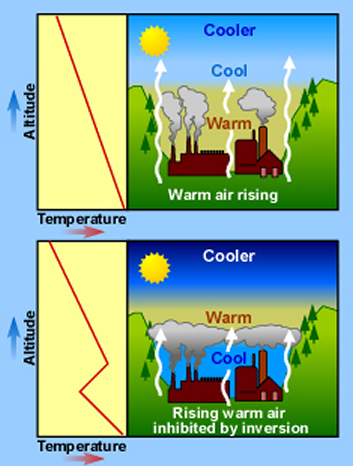

*Nguồn: Cơ quan Bảo vệ Môi trường Hoa Kỳ (USEPA)*

## 4.5. Tốc độ gió có ảnh hưởng tới chất lượng không khí không?

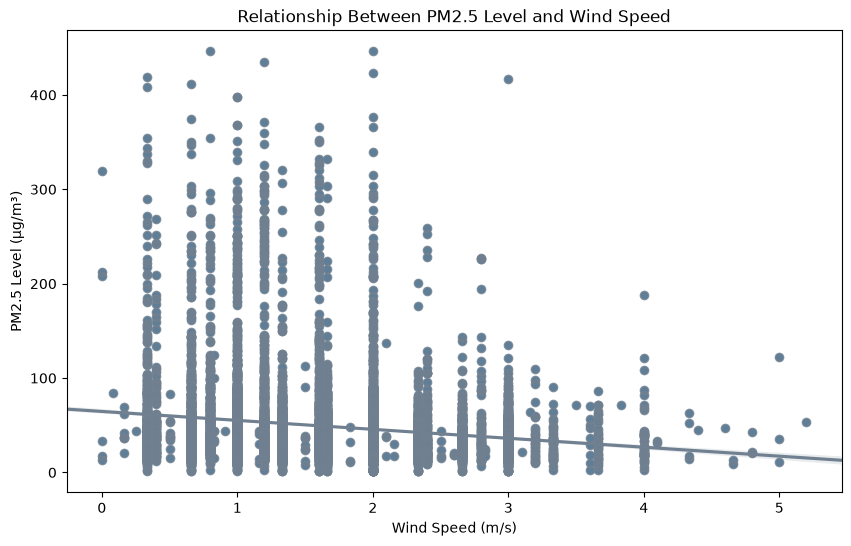

Correlation Coefficient: -0.16


In [27]:
# Biểu đồ phân tán
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Wind Speed', y='PM25')

# Vẽ đường hồi quy
sns.regplot(data=df, x='Wind Speed', y='PM25', truncate= False, color='slategray')

# Tính hệ số tương quan
correlation_coefficient = df['Wind Speed'].corr(df['PM25'])

# Thêm tiêu đề và nhãn trục
plt.title('Relationship Between PM2.5 Level and Wind Speed')
plt.xlabel('Wind Speed (m/s)')
plt.ylabel('PM2.5 Level (μg/m³)')

plt.show()

# In hệ số tương quan
print(f"Correlation Coefficient: {correlation_coefficient:.2f}")

**Nhận xét:** *Biểu đồ cho thấy hệ số tương quan âm -0.16, tức tương quan rất yếu, có thể coi là không đáng kể. Tuy nhiên, khi xem xét kỹ xu hướng và quy luật, có thể thấy gió càng mạnh thì PM2.5 càng thấp.*

*Theo giải thích của [IQAir](https://www.iqair.com/newsroom/wind-weather-air-pollution), khi chất ô nhiễm tích tụ ở một khu vực, gió đóng vai trò quan trọng trong việc phát tán chúng, giúp giảm nồng độ ô nhiễm tại khu vực đó. Quá trình này cũng có thể mang chất ô nhiễm ra xa nguồn phát thải, làm giảm tác động của chúng trên một phạm vi rộng hơn.*

# Kết luận

## Những phát hiện chính

**Thời tiết Hà Nội:**
- ***Lượng mưa***: Hà Nội có lượng mưa khá lớn trong năm qua, tổng cộng 2408.25 mm. Mùa hạ và mùa thu mưa nhiều nhất, trong đó mùa thu là mùa mưa nhiều nhất. Ngược lại, mùa xuân thường có mưa phùn, còn mùa đông là mùa khô nhất.
- ***Áp suất***: Hà Nội có áp suất thấp vào mùa hạ và mùa thu – thời điểm lượng mưa lớn.
- ***Độ ẩm***: Với độ ẩm trung bình 78.05%, Hà Nội thuộc nhóm thành phố ẩm nhất châu Á. Mùa xuân có độ ẩm cao nhất trong 4 mùa, trùng với thời điểm thường có mưa phùn.
- ***Nhiệt độ***: Nhiệt độ trung bình 25.3℃ cho thấy thành phố có khí hậu ấm áp quanh năm. Mùa nóng nhất là mùa hạ, với nhiệt độ trung bình trên 28℃.
- ***Tốc độ gió***: Hà Nội có tốc độ gió tương đối thấp trong năm qua. Mùa xuân có tốc độ gió trung bình cao nhất, có thể do ảnh hưởng của gió mùa Đông Bắc.

**Chất lượng không khí Hà Nội:**
- ***AQI***: Trung bình, AQI của Hà Nội ở mức 117.63, thuộc nhóm "Không tốt cho nhóm nhạy cảm". Chỉ số đạt mức "Nguy hại" (>300) vào nhiều thời điểm từ tháng 11 đến giữa tháng 2. Giải thích cho hiện tượng này, Cục Kiểm soát ô nhiễm môi trường cho biết thời tiết hanh khô ở Hà Nội khiến bụi phát tán trên diện rộng. Bên cạnh đó, việc đốt rác và phụ phẩm nông nghiệp cũng góp phần làm tăng mức độ ô nhiễm.
- ***PM2.5***: Các giờ có nồng độ PM2.5 cao nhất trong năm là 8h, 9h, 19h, 20h và 21h. Mùa có nồng độ PM2.5 trung bình cao nhất là mùa đông, tiếp theo là mùa xuân, mùa thu và mùa hạ.
- PM2.5 và PM10 có tương quan cao với AQI, cho thấy PM2.5 và PM10 là các yếu tố đóng góp chính vào AQI.

**Ảnh hưởng của điều kiện thời tiết tới chất lượng không khí Hà Nội:**
- Mưa càng nhiều giờ thì nồng độ PM2.5 càng thấp
- Mưa càng to thì nồng độ PM2.5 càng thấp
- Áp suất khí quyển càng cao thì nồng độ PM2.5 càng cao
- Độ ẩm không có mối quan hệ với nồng độ PM2.5
- Trời càng lạnh thì nồng độ PM2.5 càng cao
- Gió càng mạnh thì nồng độ PM2.5 càng thấp

## Khuyến nghị về chất lượng không khí

*Theo [Sở Y tế bang New York](https://www.health.ny.gov/environmental/indoors/air/pmq_a.htm#:~:text=Spend%20more%20time%20indoors.,air%20conditioning%20if%20you%20can.), khi nồng độ PM2.5 ở mức có hại, có thể thực hiện các biện pháp sau:*

**Khi ở ngoài trời:**

*- **Đeo khẩu trang:** Nếu buộc phải ra ngoài, hãy đeo khẩu trang N95 hoặc loại tương tự có khả năng lọc bụi mịn trong không khí.*

*- **Hạn chế vận động mạnh:** Tránh các hoạt động gắng sức như chạy bộ hay đạp xe. Nên thở nhẹ nếu có thể, vì hít thở sâu sẽ đưa nhiều không khí ô nhiễm vào cơ thể hơn.*

*- **Đi chung xe:** Tận dụng tối đa chỗ ngồi trên xe cá nhân để giảm lượng PM2.5 phát thải từ giao thông.*

**Khi ở trong nhà:**

*- **Đóng cửa sổ và cửa ra vào:** Nên đóng kín cửa để ngăn không khí ô nhiễm từ bên ngoài lọt vào.*

*- **Dùng máy lọc không khí:** Cân nhắc sử dụng máy lọc không khí có màng lọc HEPA, loại có thể loại bỏ hiệu quả các hạt PM2.5 trong không khí.*